<a href="https://colab.research.google.com/github/pakizahassan/Intro-to-CV/blob/main/Lab12_Quiz_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# fa23-bai-034

# CNN Feature Visualization, Parameter Audit & Critical Analysis

Imports & Image Loading

Loaded: /content/drive/MyDrive/Intro to CV/steel_facade.jpeg | Shape: (256, 256) | Range: [0.00, 1.00]


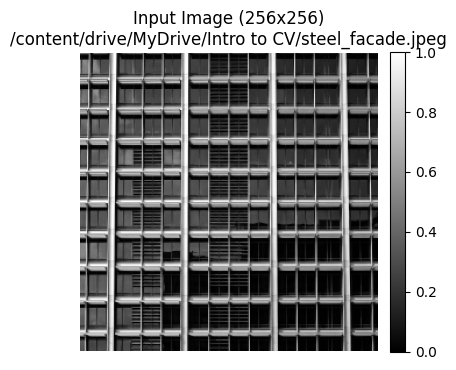

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load the new steel-and-glass facade (falls back to skimage.data.camera() if not found)
IMAGE_PATH = "/content/drive/MyDrive/Intro to CV/steel_facade.jpeg"

if os.path.exists(IMAGE_PATH):
    raw_img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
    source_label = IMAGE_PATH
else:
    raw_img = data.camera()
    source_label = "skimage.data.camera() (fallback)"

# Resize to 256x256 and normalize to float32 in [0.0, 1.0]
img_gray = cv2.resize(raw_img, (256, 256), interpolation=cv2.INTER_AREA)
img_norm = img_gray.astype(np.float32) / 255.0

print(f"Loaded: {source_label} | Shape: {img_norm.shape} | Range: [{img_norm.min():.2f}, {img_norm.max():.2f}]")

plt.figure(figsize=(4.2, 4.2))
plt.imshow(img_norm, cmap="gray")
plt.title(f"Input Image (256x256)\n{source_label}")
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis("off")
plt.show()

Part I — Pure NumPy/OpenCV Filter Pipeline (5 Kernels × 4 Stages)

In [ ]:
def apply_relu(x: np.ndarray) -> np.ndarray:
    """Stage B: Element-wise ReLU activation max(0, x)."""
    return np.maximum(0.0, x)

def apply_max_pool2d(x: np.ndarray, k: int = 2) -> np.ndarray:
    """Stage C: Non-overlapping kxk Max Pooling (stride k)."""
    h, w = x.shape
    h_trim, w_trim = (h // k) * k, (w // k) * k
    return x[:h_trim, :w_trim].reshape(h_trim // k, k, w_trim // k, k).max(axis=(1, 3))

def apply_avg_pool2d(x: np.ndarray, k: int = 2) -> np.ndarray:
    """Stage D: Non-overlapping kxk Average Pooling (stride k)."""
    h, w = x.shape
    h_trim, w_trim = (h // k) * k, (w // k) * k
    return x[:h_trim, :w_trim].reshape(h_trim // k, k, w_trim // k, k).mean(axis=(1, 3))

# Define 5 custom 3x3 kernels (Prewitt Horizontal, Sobel Vertical, Sharpen, Box Blur, Emboss)
custom_kernels = {
    "1. Horizontal Edge\n(Prewitt)": np.array([
        [ 1,  1,  1],
        [ 0,  0,  0],
        [-1, -1, -1]
    ], dtype=np.float32),

    "2. Vertical Edge\n(Sobel-Y / Vert.)": np.array([
        [ 1,  0, -1],
        [ 2,  0, -2],
        [ 1,  0, -1]
    ], dtype=np.float32),

    "3. Sharpen\nKernel": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32),

    "4. Box Blur\n(3x3 Mean)": np.ones((3, 3), dtype=np.float32) / 9.0,

    "5. Emboss\nKernel": np.array([
        [-2, -1,  0],
        [-1,  1,  1],
        [ 0,  1,  2]
    ], dtype=np.float32),
}

pipeline_outputs = {}
print(f"{'Filter':<24} | {'Stage A (min, max, %<0)':<26} | {'Stage B (%==0)':<14} | {'Stage C MaxP (mean, max)':<24} | {'Stage D AvgP (mean, max)'}")
print("-" * 118)

for label, kernel in custom_kernels.items():
    # Stage A: Raw Convolution (CV_32F preserves negative activations; BORDER_CONSTANT = zero padding)
    stage_a = cv2.filter2D(img_norm, ddepth=cv2.CV_32F, kernel=kernel, borderType=cv2.BORDER_CONSTANT)
    # Stage B: Post-ReLU
    stage_b = apply_relu(stage_a)
    # Stage C: 2x2 Max Pooling (stride 2)
    stage_c = apply_max_pool2d(stage_b, k=2)
    # Stage D: 2x2 Average Pooling (stride 2)
    stage_d = apply_avg_pool2d(stage_b, k=2)

    pipeline_outputs[label] = (stage_a, stage_b, stage_c, stage_d)

    short = label.replace("\n", " ")[:23]
    neg_pct = (stage_a < 0).mean() * 100
    zero_pct = (stage_b == 0).mean() * 100
    print(f"{short:<24} | ({stage_a.min():5.2f}, {stage_a.max():5.2f}, {neg_pct:5.1f}%) | {zero_pct:6.1f}%        | "
          f"{stage_c.mean():6.4f}, {stage_c.max():5.2f}            | {stage_d.mean():6.4f}, {stage_d.max():5.2f}")

Filter                   | Stage A (min, max, %<0)    | Stage B (%==0) | Stage C MaxP (mean, max) | Stage D AvgP (mean, max)
----------------------------------------------------------------------------------------------------------------------
1. Horizontal Edge (Pre  | (-2.93,  2.48,  54.9%) |   55.5%        | 0.2774,  2.48            | 0.1724,  1.93
2. Vertical Edge (Sobel  | (-3.58,  3.86,  56.0%) |   58.9%        | 0.3782,  3.86            | 0.2227,  3.64
3. Sharpen Kernel        | (-1.57,  2.89,  27.7%) |   27.8%        | 0.6195,  2.89            | 0.3812,  1.79
4. Box Blur (3x3 Mean)   | ( 0.00,  0.99,   0.0%) |    0.0%        | 0.3614,  0.99            | 0.3169,  0.96
5. Emboss Kernel         | (-2.77,  4.35,  29.5%) |   29.5%        | 0.7718,  4.35            | 0.5083,  2.94


Part I — Unified $5 \times 4$ Comparative Visualization Grid

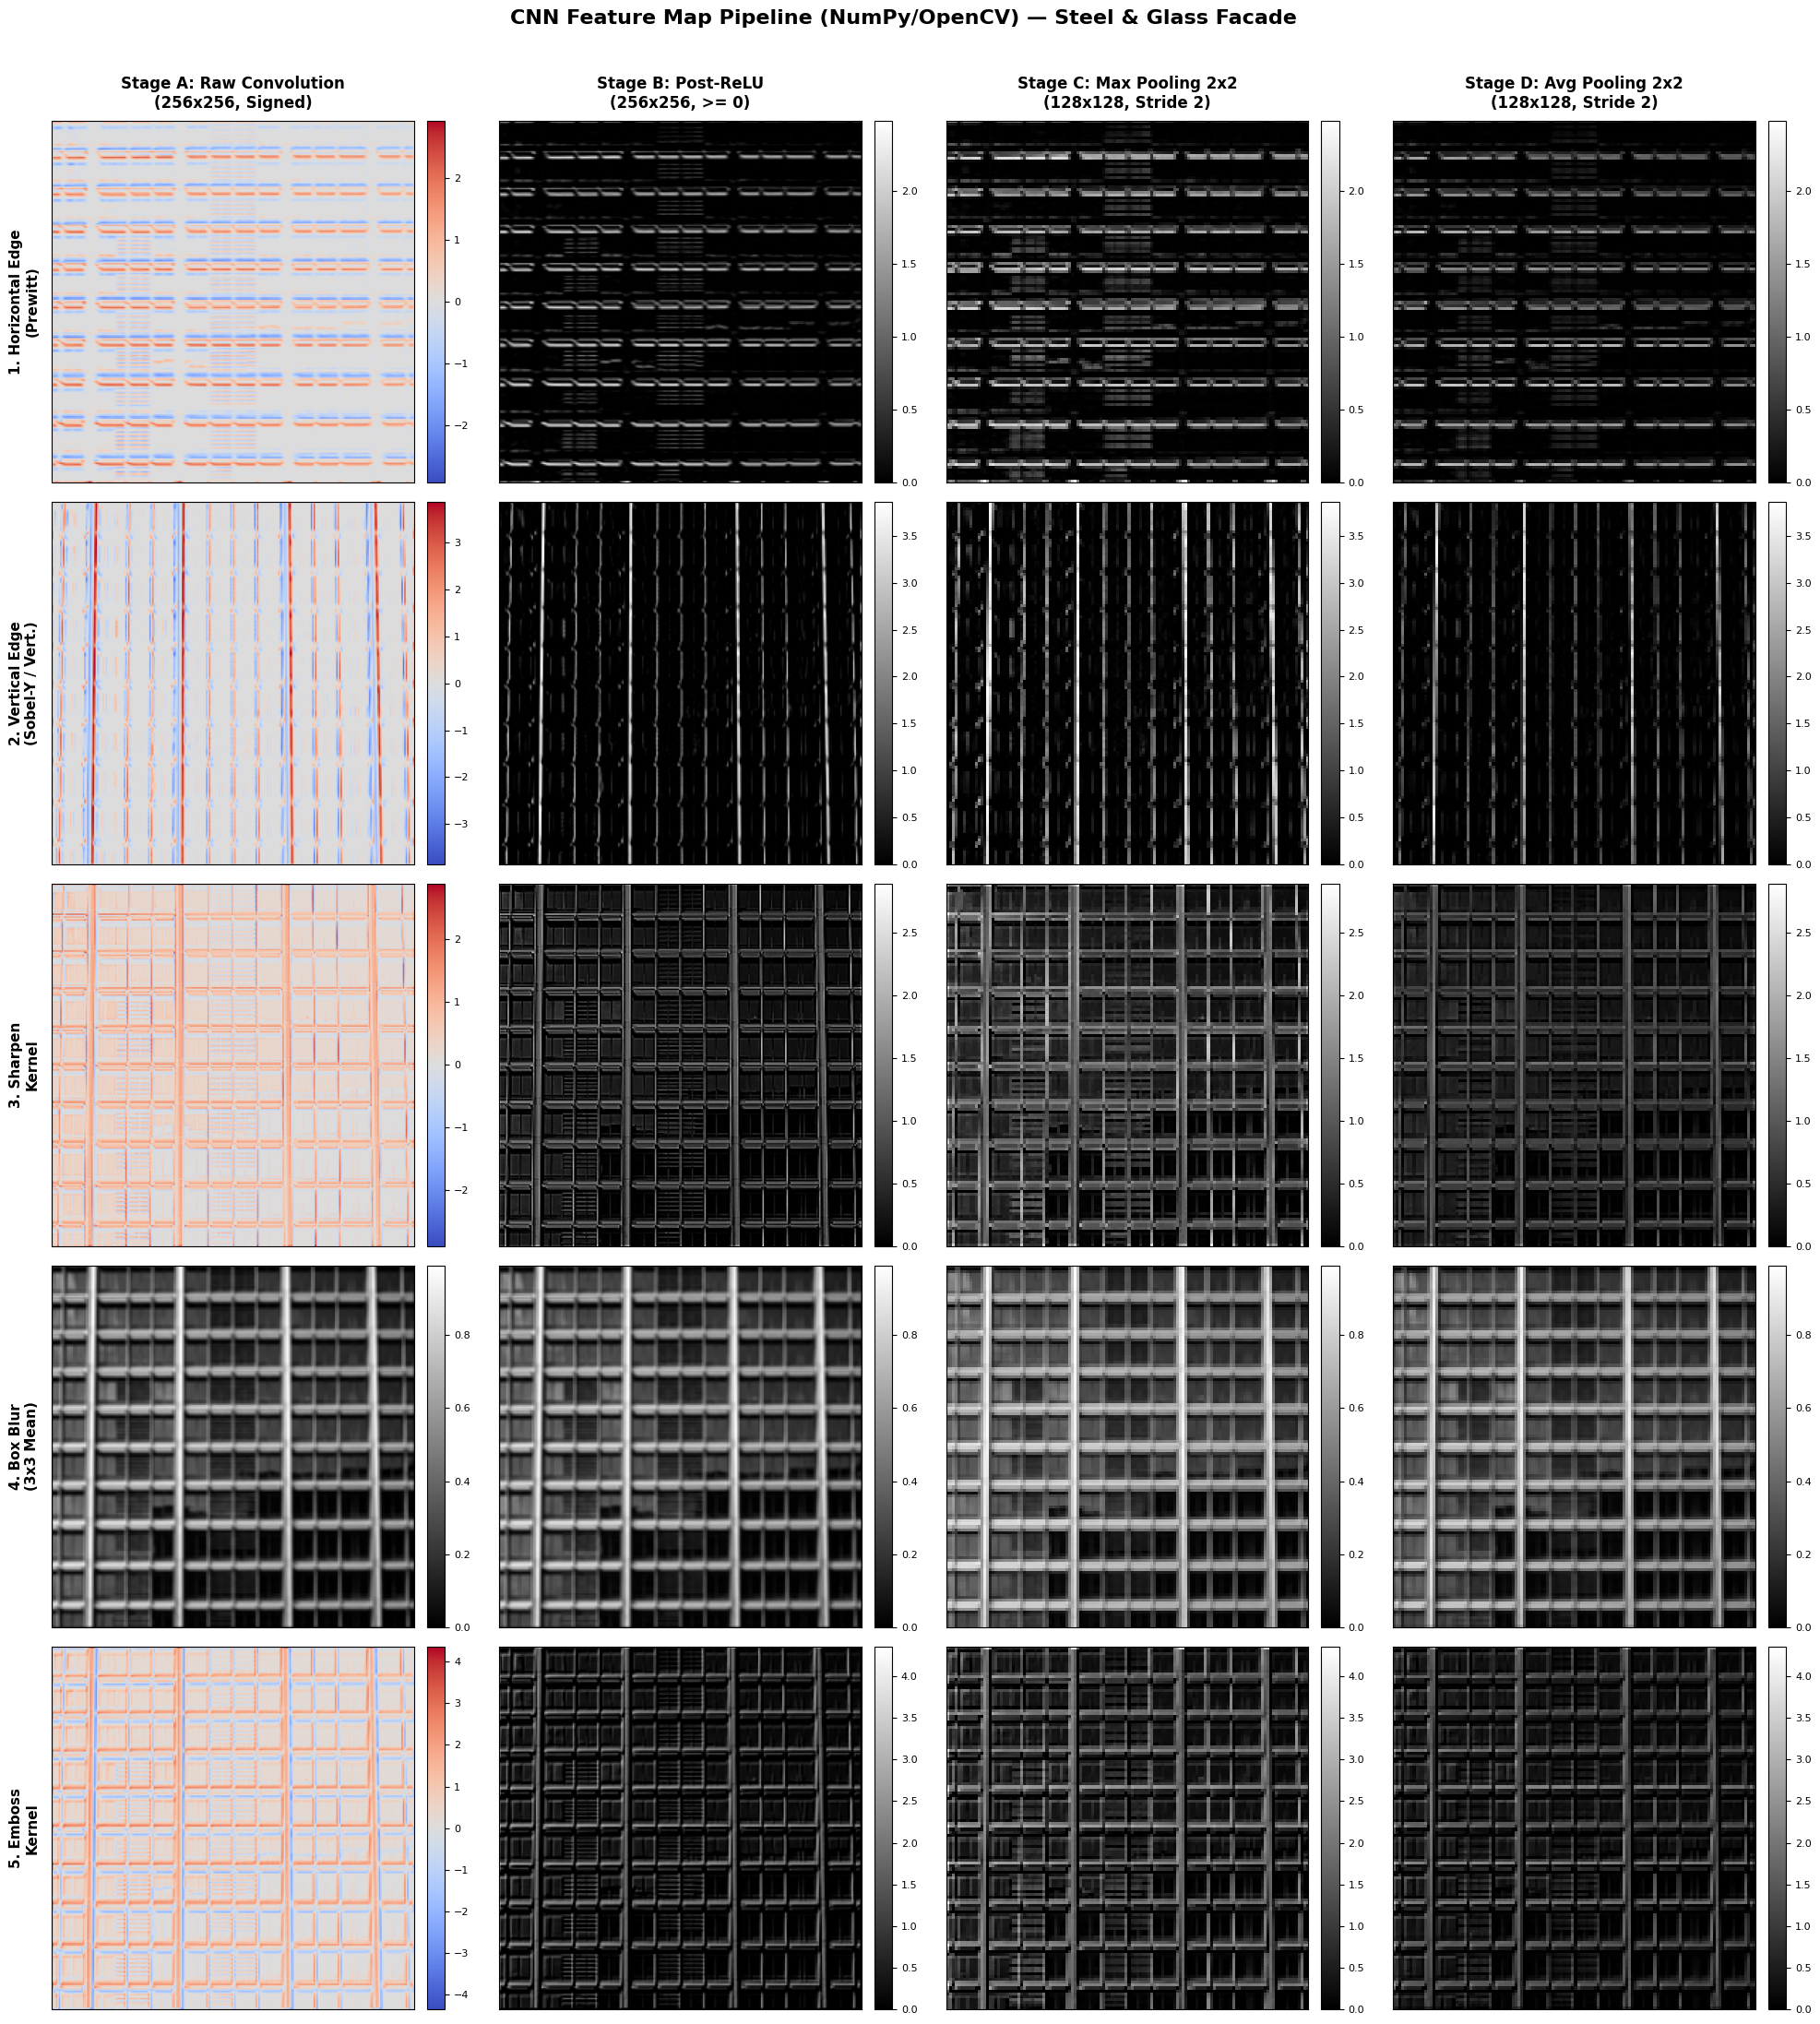

In [ ]:
col_headers = [
    "Stage A: Raw Convolution\n(256x256, Signed)",
    "Stage B: Post-ReLU\n(256x256, >= 0)",
    "Stage C: Max Pooling 2x2\n(128x128, Stride 2)",
    "Stage D: Avg Pooling 2x2\n(128x128, Stride 2)"
]

fig, axes = plt.subplots(5, 4, figsize=(20, 22))
fig.suptitle("CNN Feature Map Pipeline (NumPy/OpenCV) — Steel & Glass Facade", fontsize=16, fontweight="bold", y=0.995)

for r, (label, stages) in enumerate(pipeline_outputs.items()):
    stage_a, stage_b, stage_c, stage_d = stages
    shared_max = max(float(stage_b.max()), 1e-5)

    for c, fmap in enumerate(stages):
        ax = axes[r, c]
        if c == 0 and fmap.min() < 0:
            bound = max(abs(float(fmap.min())), abs(float(fmap.max())))
            im = ax.imshow(fmap, cmap="coolwarm", vmin=-bound, vmax=bound)
        else:
            im = ax.imshow(fmap, cmap="gray", vmin=0.0, vmax=shared_max)

        if r == 0:
            ax.set_title(col_headers[c], fontsize=12, fontweight="bold", pad=10)
        if c == 0:
            ax.set_ylabel(label, fontsize=11, fontweight="bold", labelpad=10)

        ax.set_xticks([])
        ax.set_yticks([])
        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
        cbar.ax.tick_params(labelsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.savefig("cnn_5x4_grid_steel_facade.png", dpi=200, bbox_inches="tight")
plt.show()

Part II — PyTorch Architectural Comparison & Parameter Audit

In [ ]:
import torch
import torch.nn as nn

class LightweightCNN(nn.Module):
    def __init__(self, kernel_size: int, pool_type: str = "max"):
        super().__init__()
        pool_cls = nn.MaxPool2d if pool_type == "max" else nn.AvgPool2d

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=5, kernel_size=kernel_size)
        self.relu1 = nn.ReLU()
        self.pool1 = pool_cls(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(in_channels=5, out_channels=10, kernel_size=kernel_size)
        self.relu2 = nn.ReLU()
        self.pool2 = pool_cls(kernel_size=2, stride=2)

        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(in_features=10, out_features=10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(self.gap(x))
        return self.fc(x)

def print_pytorch_summary(model: nn.Module, title: str, input_size=(1, 3, 32, 32)):
    """Runs a dummy forward pass and prints a Keras-style layer & parameter table."""
    print(f"\n{'=' * 72}\n{title}\n{'=' * 72}")
    print(f"{'Layer (Name)':<24} | {'Output Shape':<22} | {'Trainable Params':>16}")
    print("-" * 72)

    x = torch.zeros(input_size)
    total_params = 0
    for name, module in model.named_children():
        x = module(x)
        params = sum(p.numel() for p in module.parameters() if p.requires_grad)
        total_params += params
        print(f"{name:<24} | {str(list(x.shape)):<22} | {params:>16,}")

    print("-" * 72)
    print(f"{'Total Trainable Parameters':<49} | {total_params:>16,}")
    return total_params

model_a = LightweightCNN(kernel_size=3, pool_type="max")
model_b = LightweightCNN(kernel_size=5, pool_type="avg")

total_a = print_pytorch_summary(model_a, "Model A (Standard): 3x3 Kernels + MaxPool 2x2 (stride 2)")
total_b = print_pytorch_summary(model_b, "Model B (Large Kernel): 5x5 Kernels + AvgPool 2x2 (stride 2)")

pct_inc = ((total_b - total_a) / total_a) * 100
print(f"\nAudit Verification -> Model A: {total_a} | Model B: {total_b} | Increase: +{pct_inc:.2f}%")


Model A (Standard): 3x3 Kernels + MaxPool 2x2 (stride 2)
Layer (Name)             | Output Shape           | Trainable Params
------------------------------------------------------------------------
conv1                    | [1, 5, 30, 30]         |              140
relu1                    | [1, 5, 30, 30]         |                0
pool1                    | [1, 5, 15, 15]         |                0
conv2                    | [1, 10, 13, 13]        |              460
relu2                    | [1, 10, 13, 13]        |                0
pool2                    | [1, 10, 6, 6]          |                0
gap                      | [1, 10, 1, 1]          |                0
flatten                  | [1, 10]                |                0
fc                       | [1, 10]                |              110
------------------------------------------------------------------------
Total Trainable Parameters                        |              710

Model B (Large Kernel): 5x5 Kernels 